# 02 — Instruments, presets and the array

Every number the ETC uses is an input: the instrument preset, the telescope array, the fiber and
the sky. This notebook is about the first two.

In this notebook:
1. the presets: `list_instruments()` and the mode table,
2. where the photons go: `plot_throughput()`,
3. CSHELL and its narrow echelle settings: `Instrument.setting_window()`,
4. overriding a preset: `Instrument.from_preset(**overrides)` and `replace()`,
5. the array: `Telescope(n_telescopes, fiber, combine, telescopes_per_input)`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 10, "legend.fontsize": 8})

***
## 1. The presets

Each instrument mode is a preset: a set of spectrograph and detector parameters loaded by name.
The `bench_*` presets are the WIYN Bench grating and order combinations that reach 400 nm
([the WIYN table](https://www.wiyn.org/Instruments/wiynbench.html)), scaled from the reference
`bench_r1800` mode; the `cshell_*` presets are CSHELL at R = 18,000 (bare fiber), 21,500 and
43,000 (100 um slit). *One setting* is the wavelength range a single exposure covers: the whole
range for the Bench, but only one free spectral range (~2.5e-3 $\lambda$) for CSHELL. `n_pix` is
the extraction aperture per resel (dispersion pixels times the fiber-image height). The CSHELL slit
throughputs at R = 21,500 and 43,000 and the flat QEs are placeholders.

In [2]:
rows = {}
for name in list_instruments():
    ins = Instrument.from_preset(name)
    lo, hi = ins.setting_window(0.5 * (ins.wavelength_min_nm + ins.wavelength_max_nm))
    rows[name] = {"description": ins.description, "R": int(ins.resolving_power),
                  "range (nm)": f"{ins.wavelength_min_nm:.0f}-{ins.wavelength_max_nm:.0f}",
                  "one setting at centre (nm)": round(hi - lo, 1),
                  "efficiency": ins.efficiency, "QE": ins.qe, "pix/resel": ins.pixels_per_resel, "n_pix": ins.n_pix,
                  "read noise (e-)": ins.read_noise, "dark (e-/s/pix)": ins.dark_current,
                  "min exptime (s)": ins.min_exptime}
modes = pd.DataFrame(rows).T.rename_axis("preset")
modes

,description,R,range (nm),one setting at centre (nm),efficiency,QE,pix/resel,n_pix,read noise (e-),dark (e-/s/pix),min exptime (s)
preset,,,,,,,,,,,
bench_1200_28p7_o1,"WIYN Bench, 1200 @ 28.7 deg, order 1, 688-812 ...",6910,688-812,123.0,0.229,0.75,2.2,4.84,3.7,0.0003,1.0
bench_1200_28p7_o2,"WIYN Bench, 1200 @ 28.7 deg, order 2, 400-431 ...",7561,400-431,30.8,0.229,0.75,2.2,4.84,3.7,0.0003,1.0
bench_316_63p4_o9,"WIYN Bench, 316 @ 63.4 deg, order 9, 644-669 n...",31284,644-669,25.0,0.208,0.75,2.2,4.84,3.7,0.0003,1.0
bench_316_7p0_o1,"WIYN Bench, 316 @ 7.0 deg, order 1, 486-1014 n...",1438,486-1014,529.0,0.292,0.75,2.2,4.84,3.7,0.0003,1.0
bench_316_7p0_o2,"WIYN Bench, 316 @ 7.0 deg, order 2, 400-507 nm...",1438,400-507,107.2,0.292,0.75,2.2,4.84,3.7,0.0003,1.0
bench_3300vph_o1,"WIYN Bench, 3300 VPH, order 1, 498-526 nm, R~1...",18108,498-526,27.2,0.3,0.75,2.2,4.84,3.7,0.0003,1.0
bench_400_4p2_o1,"WIYN Bench, 400 @ 4.2 deg, order 1, 400-710 nm...",1202,400-710,310.0,0.292,0.75,2.2,4.84,3.7,0.0003,1.0
bench_600_13p9_o1,"WIYN Bench, 600 @ 13.9 deg, order 1, 614-886 n...",2875,614-886,272.4,0.292,0.75,2.2,4.84,3.7,0.0003,1.0
bench_600_13p9_o2,"WIYN Bench, 600 @ 13.9 deg, order 2, 400-448 n...",2913,400-448,48.1,0.292,0.75,2.2,4.84,3.7,0.0003,1.0


`describe()` on an instrument, a telescope, a sky or the whole ETC prints the same information as
text.

In [3]:
etc = LFASTETC("bench_r1800", n_telescopes=20)
etc.describe()

'bench_r1800: R=1800, 412-686 nm, 2.2x2.2 pix/resel (tophat), S_opt=0.3, slit=1.0, RN=3.7 e-, dark=0.0003 e-/s/pix | 20 x 0.726 m telescopes (total area 8.28 m^2, 3.2 m equivalent), 18um fiber (1.48" on sky), combine=fiber, 1 input(s) | SkyCalc table skytable_secz1.3.fits x 1 | gaussian LSF, 8x oversampled pixels'

***
## 2. Where the photons go

$K_{opt}$ is the end-to-end telescope throughput for a point source, and it already contains the
fiber injection efficiency $\eta_{fib}$ and the atmospheric extinction at the reference airmass
(that is how Choi et al. define it). The sky fills the fiber uniformly and pays no injection loss,
so it sees $K_{opt}/\eta_{fib}$. The spectrograph efficiency and the detector QE are flat
placeholders in the presets. The black curve is the product of everything, and it is low: a few
percent of the photons that hit the primary mirrors end up as detected electrons.

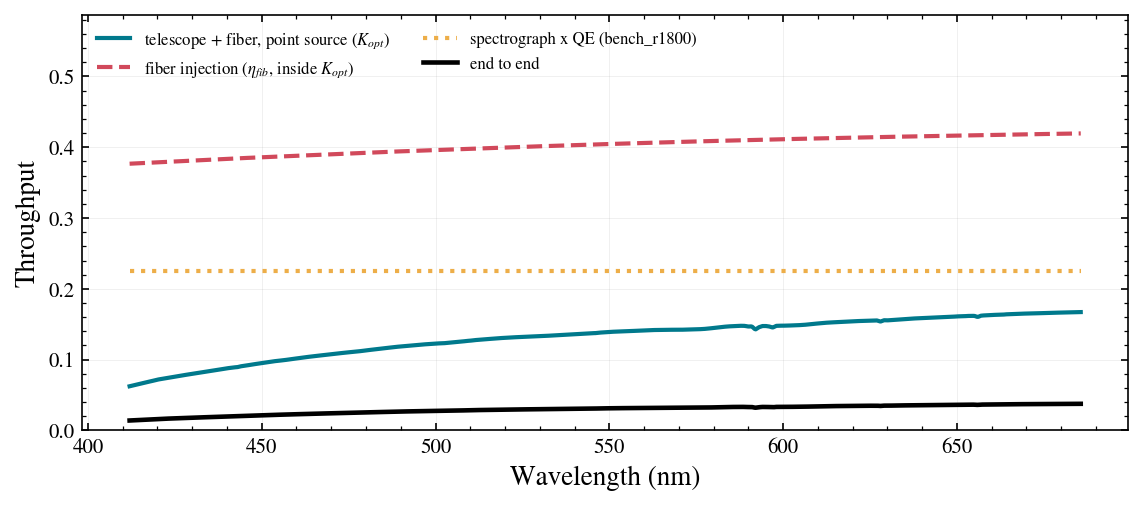

In [4]:
etc.plot_throughput();

> 🤖 **Ask Jupyter AI:** *Plot the total throughput of every bench_* preset on one axis over its own wavelength range, using LFASTETC(name).plot_throughput or etc.throughputs(). Which mode is the most efficient at 650 nm?*

***
## 3. CSHELL: one echelle setting at a time

CSHELL is a single-order echelle: its free spectral range is only ~2.5e-3 $\lambda$, so one setting
covers a narrow window (~3 nm at 1.08 um, ~4 nm at 1.55 um). `Instrument.setting_window(center_nm)`
returns the window of one setting, which is then passed to the ETC to restrict the wavelength grid.
Building the full-range CSHELL ETC is also allowed; its results are then "what each setting would
give", not one exposure.

In [5]:
cs = Instrument.from_preset("cshell_r18000")
lo, hi = cs.setting_window(1555.0)
print(f"One CSHELL setting centred on 1555 nm covers {lo:.1f}-{hi:.1f} nm ({10 * (hi - lo):.0f} A)")

cshell = LFASTETC(cs, wavelength_min_nm=lo, wavelength_max_nm=hi)
kstar = Source.blackbody(4500, mag=9, band="H")
r = cshell.snr(kstar, exptime=300)
print(f"H=9 K star, 300 s: median SNR/resel = {np.nanmedian(r.snr):.1f} | peak = {np.nanmax(r.peak_e_per_pixel):.0f} e-/pix | saturated: {bool(r.saturated.any())}")

One CSHELL setting centred on 1555 nm covers 1553.1-1556.9 nm (39 A)
H=9 K star, 300 s: median SNR/resel = 38.3 | peak = 475 e-/pix | saturated: False


***
## 4. Overriding a preset

Every preset field can be changed, which is how to test design choices:
`Instrument.from_preset(name, **overrides)` builds a modified preset and `instrument.replace(...)`
copies an existing one with some fields changed. For example, what would a lower-noise detector
buy CSHELL? Here its read noise drops from 22 to 5 e-.

> ✏️ **Before you run the next cell:** CSHELL's read noise drops from 22 to 5 e- on each of the 36 pixels of the extraction aperture. Does the SNR of the H = 9 star above go up by 10%, 50% or a factor 4? Write your guess down (or put it in the room poll), then run.

In [6]:
low_rn = cs.replace(read_noise=5.0)
r2 = LFASTETC(low_rn, wavelength_min_nm=lo, wavelength_max_nm=hi).snr(kstar, exptime=300)
for label, rr, ins in (("preset", r, cs), ("override", r2, low_rn)):
    print(f"{label:8s}: read noise {ins.read_noise:4.0f} e-  ->  median SNR/resel = {np.nanmedian(rr.snr):.1f}")

preset  : read noise   22 e-  ->  median SNR/resel = 38.3
override: read noise    5 e-  ->  median SNR/resel = 57.9


At H = 9 the star gives ~6600 e$^-$ per resel in 300 s, but the read noise, 22 e$^-$ on each of the
36 pixels, adds a variance of ~17,000 e$^{-2}$, more than the star's own photon noise. Lowering it
to 5 e$^-$ raises the SNR by ~50%; for fainter targets the gain is larger still.

***
## 5. The array

The number of telescopes is an ordinary parameter. `Telescope` holds the array:

- `n_telescopes`: how many 0.726 m units;
- `fiber`: `"18um"` (goes through the fiber combiner) or `"50um"` (does not);
- `combine`: `"fiber"` (the telescopes of one array feed one spectrograph input: signal and sky
  per pixel grow with $N$, detector noise is paid once per input) or `"independent"` (each
  telescope produces its own spectrum, co-added afterwards, SNR $\propto \sqrt{N}$);
- `telescopes_per_input`: beyond 20 telescopes the ETC assumes one combiner input per 20-telescope
  array (the default), read out separately and co-added; `None` is an idealised single combiner.

`etc.telescope` reports the derived numbers: inputs, total area, equivalent single-dish diameter.

In [7]:
for n in (1, 20, 200):
    t = Telescope(n_telescopes=n)
    print(f"N={n:3d}: {t.n_inputs} input(s), {t.total_area_m2:5.1f} m2, equivalent diameter {t.equivalent_diameter_m:.1f} m")

N=  1: 1 input(s),   0.4 m2, equivalent diameter 0.7 m
N= 20: 1 input(s),   8.3 m2, equivalent diameter 3.2 m
N=200: 10 input(s),  82.8 m2, equivalent diameter 10.3 m


> ✏️ **Before you run the next cell:** going from 20 to 200 telescopes with the 18 um fiber: does the exposure time for a V = 19 star at SNR 10 drop by a factor 10, more, or less? Write your guess down (or put it in the room poll), then run.

In [8]:
faint = Source.blackbody(5800, mag=19, band="V")
rows = {}
for n in (20, 100, 200):
    row = {}
    for fiber in ("18um", "50um"):
        e = LFASTETC("bench_r1800", telescope=Telescope(n_telescopes=n, fiber=fiber))
        row[f"{fiber} inputs"] = e.telescope.n_inputs
        row[f"{fiber} time (min)"] = round(float(np.nanmedian(e.exptime(faint, snr=10).exptime)) / 60, 1)
    rows[n] = row
pd.DataFrame(rows).T.rename_axis("N telescopes").astype({"18um inputs": int, "50um inputs": int})

,18um inputs,18um time (min),50um inputs,50um time (min)
N telescopes,,,,
20,1,22.1,20,29.1
100,5,5.9,100,9.4
200,10,3.6,200,6.1


With the 18 um fiber, 5x more telescopes cut the time by ~4x and 10x by ~6x. Co-adding the inputs
raises the SNR by $\sqrt{n_{inputs}}$ at fixed time; that is worth a factor $n_{inputs}$ in time
only when the sky dominates the noise, and less here because read noise still contributes for this
faint star. The 50 um fiber is slower at every N: it collects more sky per telescope and pays read
noise once per telescope. Notebook 04 maps this out against N.

***
## Summary

```python
list_instruments()                                       # the bundled presets
ins = Instrument.from_preset("cshell_r18000", read_noise=5.0)   # a preset with overrides
ins.replace(qe=0.9); ins.setting_window(1555.0)          # a copy; one echelle setting (lo, hi)
etc = LFASTETC(ins, telescope=Telescope(n_telescopes=200, fiber="18um", combine="fiber", telescopes_per_input=20),
               wavelength_min_nm=lo, wavelength_max_nm=hi)
etc.plot_throughput(); etc.describe(); etc.telescope.equivalent_diameter_m
```

Next: [03 — sources, sky and the noise budget](03_sources_sky_noise.ipynb).